<a href="https://colab.research.google.com/github/Bindiya-Anand/IndiaKart_E-Commerce_Analytics/blob/main/Notebooks/Phase2_EDA_Bindiya_Anand.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Internmo Data Analytics Project 1
## IndiaKart - E-Com
### Data Analyst Intern: Bindiya Anand
#### Intern Id: Inter563


# Phase 2: Exploratory Data Analysis

In [1]:
# importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# loading orders dataset
orders = pd.read_csv('orders DA.csv')
orders.head()

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,order_id,customer_id,order_date,order_time,status,city,state,pincode,total_amount,gst_amount,shipping_charge,discount_amount,final_amount,payment_method,shipping_partner,tracking_id,delivered_date,is_cod,channel
0,ORD000001,CUST02946,22-05-2025,17:10:00,Processing,Pune,Maharashtra,300862,100984.19,16364.64,0,20486.45,100984.19,Cash on Delivery,BlueDart,TRK354572763,NaN,1,App
1,ORD000002,CUST04232,16-10-2023,05:32:00,Delivered,Ludhiana,Punjab,387852,254478.01,41599.80,0,19338.79,254478.01,UPI,DTDC,TRK272838570,19-10-2023,0,Website
2,ORD000003,CUST08078,08-10-2023,12:32:00,Cancelled,Meerut,Uttar Pradesh,294014,32557.06,3562.92,0,696.86,32557.06,Debit Card,Amazon Logistics,TRK338505401,NaN,0,App
3,ORD000004,CUST09612,02-10-2023,08:05:00,Delivered,Nashik,Maharashtra,626047,24836.94,3092.88,0,4029.94,24836.94,UPI,DTDC,TRK289792017,09-10-2023,0,Mobile Web
4,ORD000005,CUST03065,15-06-2024,20:19:00,Delivered,Moradabad,Uttar Pradesh,409210,156689.29,25092.36,0,7805.07,156689.29,UPI,Ecom Express,TRK978240041,22-06-2024,0,App


In [3]:
# converting to datetime dtype
orders['order_date'] = pd.to_datetime(orders['order_date'])
print('Data type of order_date:', orders.order_date.dtype)

Data type of order_date: datetime64[ns]


/tmp/ipykernel_1424/3800947576.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  orders['order_date'] = pd.to_datetime(orders['order_date'])


### 1. Month Order Value

In [4]:
# Create a Year-Month column for grouping
orders['year_month'] = orders['order_date'].dt.to_period('M')

# Count orders per month
monthly_orders = orders.groupby('year_month').size().reset_index(name='order_count')

# Helper columns for plotting
monthly_orders['year_month_str'] = monthly_orders['year_month'].astype(str)   # x-axis labels
monthly_orders['month_num'] = monthly_orders['year_month'].dt.month           # used to highlight Oct/Nov

# Inspect the result
display(monthly_orders[['year_month_str', 'order_count', 'month_num']])
print('Months in data:', len(monthly_orders))
print('Total orders:', monthly_orders['order_count'].sum(), '| Rows in orders:', len(orders))

,year_month_str,order_count,month_num
0,2023-06,444,6
1,2023-07,2081,7
2,2023-08,2091,8
3,2023-09,2104,9
4,2023-10,2060,10
5,2023-11,2114,11
6,2023-12,2090,12
7,2024-01,2090,1
8,2024-02,1907,2
9,2024-03,2111,3


Months in data: 25
Total orders: 50000 | Rows in orders: 50000


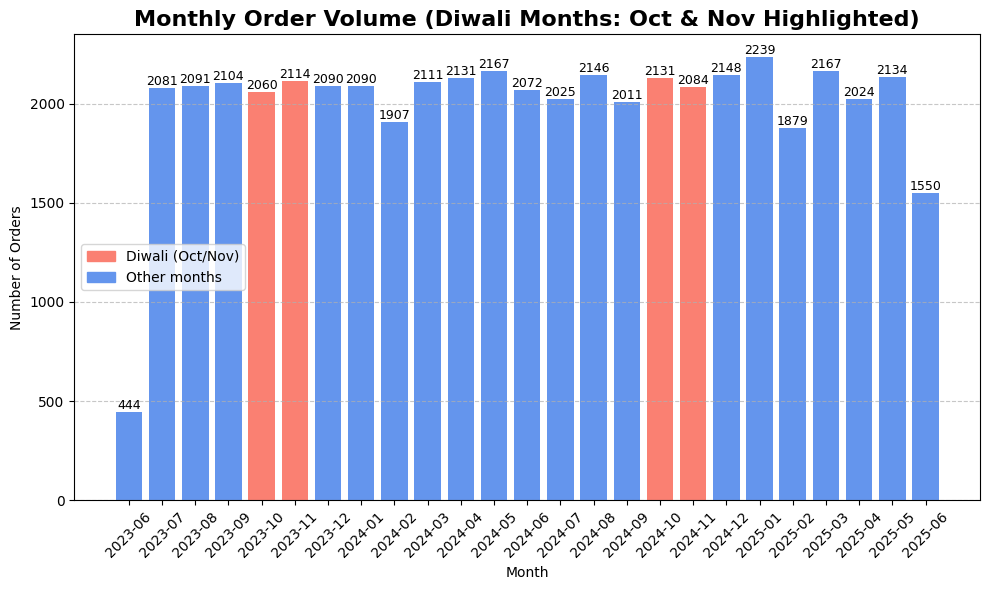

In [11]:
# Plot 1: Monthly Order Value
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.figure(figsize=(10, 6))
colors = ['salmon' if m in [10, 11] else 'cornflowerblue' for m in monthly_orders['month_num']]
bars = plt.bar(monthly_orders['year_month_str'], monthly_orders['order_count'], color=colors)

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), int(bar.get_height()),
             ha='center', va='bottom', fontsize=9)

plt.title('Monthly Order Volume (Diwali Months: Oct & Nov Highlighted)', fontsize=16, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(handles=[mpatches.Patch(color='salmon', label='Diwali (Oct/Nov)'),
                    mpatches.Patch(color='cornflowerblue', label='Other months')])
plt.tight_layout()
plt.savefig('charts/01_monthly_order_volume.png', dpi=150, bbox_inches='tight')
plt.show()

### 2. Monthly Revenue (GMV), Year-over-Year

In [18]:
# GMV per month (all statuses, final_amount)
monthly_gmv = orders.groupby('year_month')['final_amount'].sum().reset_index(name='gmv')

# Split the period into year and calendar month
monthly_gmv['year'] = monthly_gmv['year_month'].dt.year
monthly_gmv['month_num'] = monthly_gmv['year_month'].dt.month

# Pivot: rows = calendar month, columns = year, values = GMV
gmv_yoy = monthly_gmv.pivot(index='month_num', columns='year', values='gmv')

# Replace month numbers with names (safe even if a month is missing)
month_names = {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun',
               7:'Jul', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'}
gmv_yoy.index = gmv_yoy.index.map(month_names)

# Inspect the result
display(monthly_gmv)
display(gmv_yoy)
print('Total GMV in table:', monthly_gmv['gmv'].sum())
print('Total GMV in orders:', orders['final_amount'].sum())

,year_month,gmv,year,month_num
0,2023-06,2.738485e+07,2023,6
1,2023-07,1.289205e+08,2023,7
2,2023-08,1.281220e+08,2023,8
3,2023-09,1.374625e+08,2023,9
4,2023-10,1.324709e+08,2023,10
5,2023-11,1.372634e+08,2023,11
6,2023-12,1.369234e+08,2023,12
7,2024-01,1.314500e+08,2024,1
8,2024-02,1.209459e+08,2024,2
9,2024-03,1.336701e+08,2024,3


year,2023,2024,2025
month_num,,,
Jan,NaN,1.314500e+08,1.379291e+08
Feb,NaN,1.209459e+08,1.141167e+08
Mar,NaN,1.336701e+08,1.364932e+08
Apr,NaN,1.315097e+08,1.308222e+08
May,NaN,1.363584e+08,1.358494e+08
Jun,2.738485e+07,1.237410e+08,1.036033e+08
Jul,1.289205e+08,1.270283e+08,NaN
Aug,1.281220e+08,1.319235e+08,NaN
Sep,1.374625e+08,1.305253e+08,NaN


Total GMV in table: 3147385544.5800004
Total GMV in orders: 3147385544.58


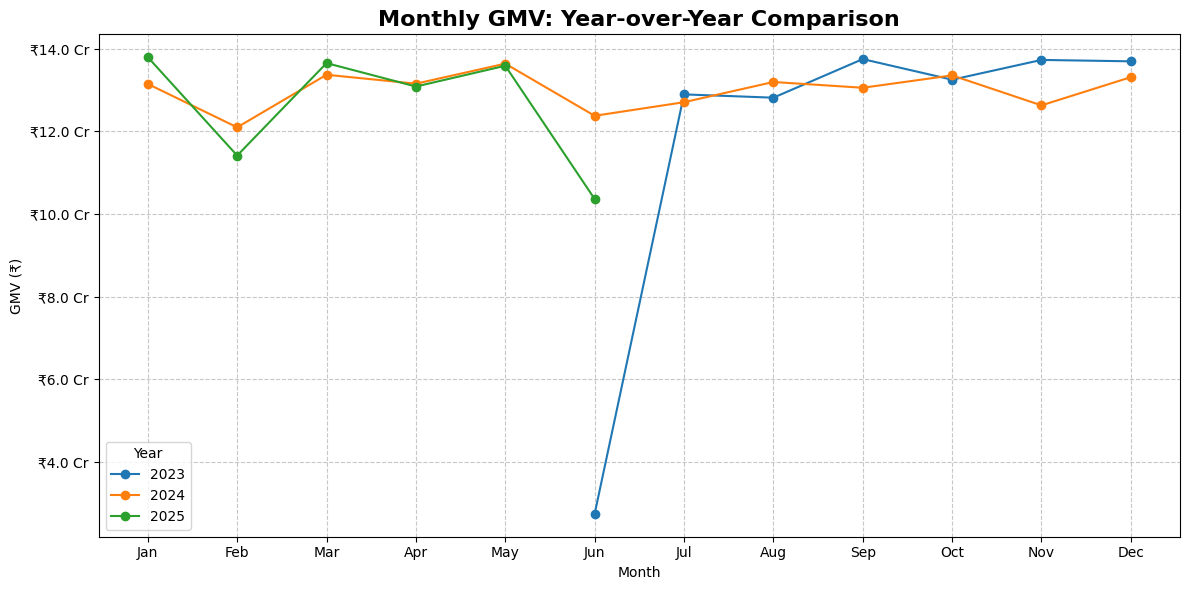

In [19]:
# Plot 2: Monthly Revenue (GMV), Year-over-Year
plt.figure(figsize=(12, 6))
for year in gmv_yoy.columns:
    plt.plot(gmv_yoy.index, gmv_yoy[year], marker='o', label=str(year))

plt.gca().yaxis.set_major_formatter(inr)
plt.title('Monthly GMV: Year-over-Year Comparison', fontsize=16, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('GMV (₹)')
plt.legend(title='Year')
plt.grid(linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('charts/02_monthly_gmv_yoy.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
# loading order_items dataset
order_items = pd.read_csv('order_items DA.csv')
order_items.head()

,item_id,order_id,product_id,product_name,category,quantity,unit_price,gst_rate,gst_amount,discount_amount,total_price
0,ITM0000001,ORD000001,PRD0522,HCL Cricket Bat Ultra,Sports & Fitness,1.0,40989.0,12.0,4918.68,7861.45,38046.23
1,ITM0000002,ORD000001,PRD0094,Berger Router Pro,Electronics,1.0,62532.0,18.0,11255.76,12373.11,61414.65
2,ITM0000003,ORD000001,PRD0613,Voltas Educational Toy Standard,Toys & Baby,1.0,1585.0,12.0,190.20,251.89,1523.31
3,ITM0000004,ORD000002,PRD0556,Ambrane Cycle Standard,Sports & Fitness,3.0,1107.0,12.0,398.52,631.44,3088.08
4,ITM0000005,ORD000002,PRD0026,Pebble Tablet Premium,Electronics,2.0,114448.0,18.0,41201.28,18707.35,251389.93


### 3. Category-wise Revenue Share

In [21]:
category_revenue = (order_items.groupby('category')['total_price']
                    .sum()
                    .sort_values(ascending=False)
                    .reset_index(name='revenue'))
category_revenue['share_pct'] = category_revenue['revenue'] / category_revenue['revenue'].sum() * 100
display(category_revenue)

,category,revenue,share_pct
0,Electronics,3.367884e+08,56.575162
1,Sports & Fitness,1.050819e+08,17.652107
2,Home & Kitchen,5.172035e+07,8.688207
3,Fashion,3.160889e+07,5.309798
4,Automotive,2.593847e+07,4.357256
5,Office Supplies,1.989236e+07,3.341604
6,Toys & Baby,1.025736e+07,1.723075
7,Beauty & Health,6.990376e+06,1.174273
8,Grocery,4.051408e+06,0.680573
9,Books,2.964240e+06,0.497946


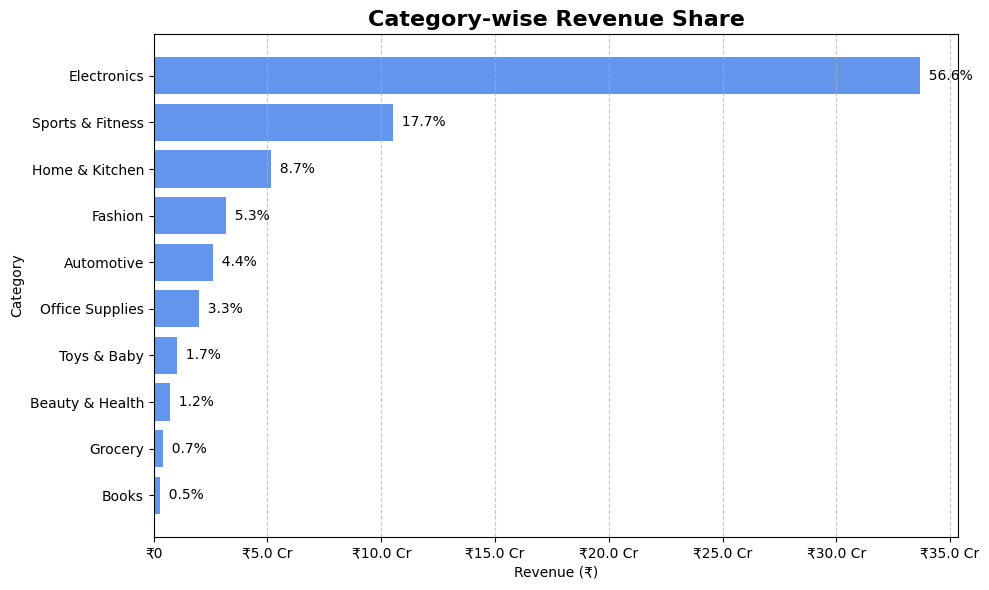

In [42]:
# Plot 3: Category-wise Revenue Share
plt.figure(figsize=(10, 6))
plt.barh(category_revenue['category'], category_revenue['revenue'], color='cornflowerblue')
plt.gca().invert_yaxis()   # biggest category on top

for i, row in category_revenue.iterrows():
    plt.text(row['revenue'], i, f"  {row['share_pct']:.1f}%", va='center')

plt.gca().xaxis.set_major_formatter(inr)
plt.title('Category-wise Revenue Share', fontsize=16, fontweight='bold')
plt.xlabel('Revenue (₹)')
plt.ylabel('Category')
plt.tight_layout()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.savefig('charts/03_category_revenue_share.png', dpi=150, bbox_inches='tight')
plt.show()

### 4. Order Status Distribution

In [25]:
status_counts = orders['status'].value_counts().reset_index()
status_counts.columns = ['status', 'order_count']
display(status_counts)

,status,order_count
0,Delivered,32499
1,Cancelled,5996
2,Shipped,5071
3,Returned,3933
4,Processing,2501


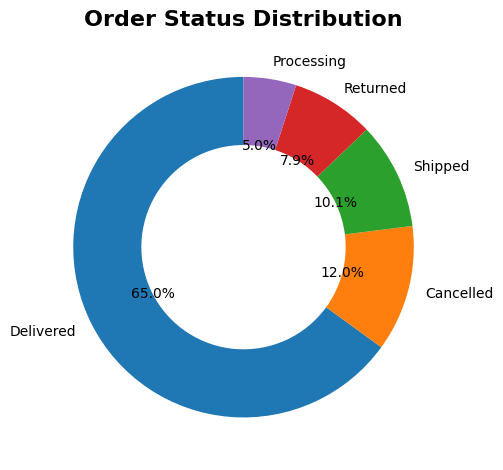

In [41]:
# Plot 4: Order Status Distribution
plt.pie(status_counts['order_count'], labels=status_counts['status'],
        autopct='%1.1f%%', startangle=90, wedgeprops={'width': 0.4})
plt.title('Order Status Distribution', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('charts/04_order_status_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

### 5. Top 10 States by Orders

In [29]:
top_states = orders['state'].value_counts().head(10).reset_index()
top_states.columns = ['state', 'order_count']
display(top_states)

,state,order_count
0,Uttar Pradesh,9507
1,Maharashtra,8179
2,Gujarat,3811
3,Madhya Pradesh,3741
4,Tamil Nadu,3664
5,Karnataka,3102
6,Rajasthan,3047
7,West Bengal,2103
8,Punjab,2073
9,Jharkhand,2044


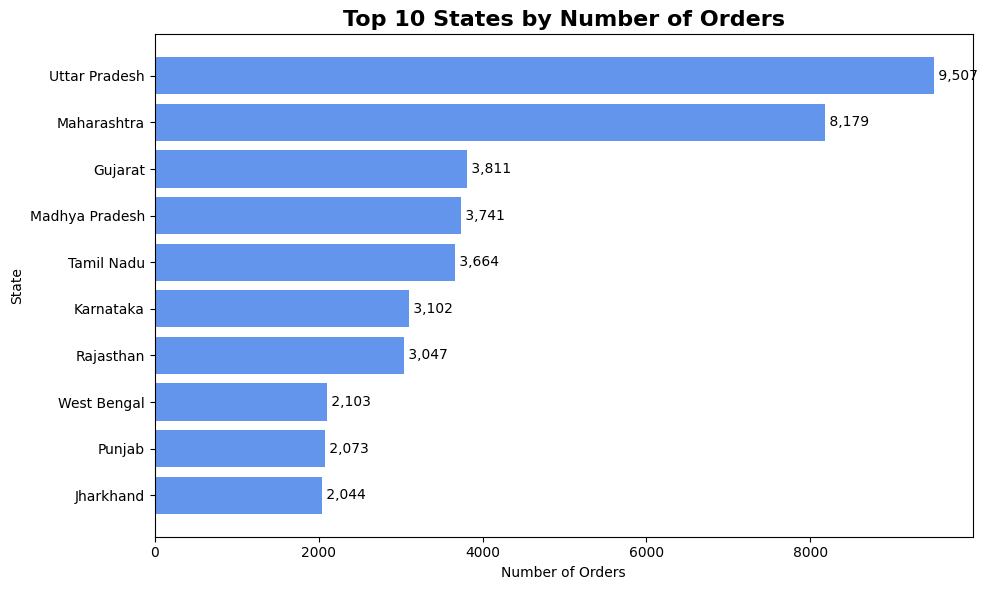

In [40]:
# Plot 5: Top 10 States by Orders
plt.figure(figsize=(10, 6))
plt.barh(top_states['state'], top_states['order_count'], color='cornflowerblue')
plt.gca().invert_yaxis()

for i, v in enumerate(top_states['order_count']):
    plt.text(v, i, f' {v:,}', va='center')

plt.title('Top 10 States by Number of Orders', fontsize=16, fontweight='bold')
plt.xlabel('Number of Orders')
plt.ylabel('State')
plt.tight_layout()
plt.savefig('charts/05_top10_states_orders.png', dpi=150, bbox_inches='tight')
plt.show()

In [32]:
# loading customers dataset
customers = pd.read_csv('customers DA.csv')
customers.head()

,customer_id,first_name,last_name,email,phone,city,state,pincode,gender,age,segment,registration_date,last_login_date,is_verified,is_active,total_orders,total_spent
0,CUST00001,Kunal,Gupta,kunal.gupta223@gmail.com,9117912889,Guwahati,Assam,314040,Male,54,New,30-07-2024,10-04-2025,0,1,7,1028341.51
1,CUST00002,Aryan,Gupta,aryan.gupta336@yahoo.in,9271550550,Navi Mumbai,Maharashtra,799535,Female,26,Budget,05-07-2023,03-05-2024,1,1,1,20337.39
2,CUST00003,Akash,Chatterjee,akash.chatterjee584@hotmail.com,9559676548,Surat,Gujarat,738196,Female,24,Regular,14-05-2022,31-10-2023,1,1,7,265688.26
3,CUST00004,Madhuri,Walia,madhuri.walia878@gmail.com,9673322422,Gwalior,Madhya Pradesh,238106,Female,23,Regular,21-01-2025,22-05-2025,1,0,7,173446.94
4,CUST00005,Vishal,Das,vishal.das342@yahoo.in,9920855521,Dhanbad,Jharkhand,783291,Female,59,Regular,06-06-2023,29-03-2024,1,0,4,239808.60


### 6. Customer Segment Distribution

In [33]:
segment_counts = customers['segment'].value_counts().reset_index()
segment_counts.columns = ['segment', 'customer_count']
display(segment_counts)

,segment,customer_count
0,Regular,4026
1,Budget,2505
2,Premium,1501
3,New,1488
4,Inactive,480


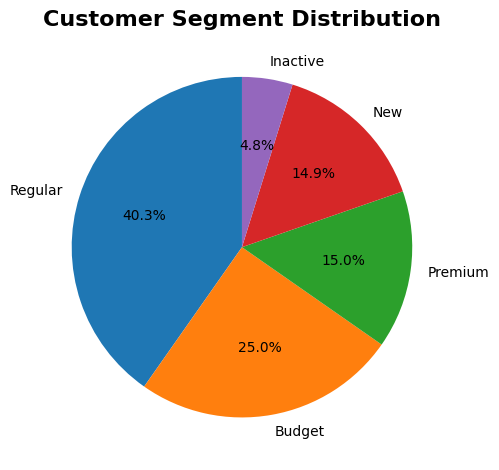

In [36]:
# Plot 6: Customer Segment Distribution
plt.pie(segment_counts['customer_count'], labels=segment_counts['segment'],
        autopct='%1.1f%%', startangle=90)
plt.title('Customer Segment Distribution', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('charts/06_customer_segment_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [37]:
# loading payments dataset
payments = pd.read_csv('payments DA.csv')
payments.head()

,payment_id,order_id,customer_id,payment_date,payment_time,payment_method,amount,status,transaction_id,bank_name,gateway,refund_amount,refund_date
0,PAY000001,ORD000001,CUST02946,22-05-2025,17:10:00,Cash on Delivery,100984.19,Success,TXN5110698474,SBI,Google Pay,0.0,NaN
1,PAY000002,ORD000002,CUST04232,16-10-2023,05:32:00,UPI,254478.01,Success,TXN4067460377,IndusInd,Google Pay,0.0,NaN
2,PAY000003,ORD000003,CUST08078,08-10-2023,12:32:00,Debit Card,32557.06,Success,TXN7056710694,Axis Bank,PhonePe,0.0,NaN
3,PAY000004,ORD000004,CUST09612,02-10-2023,08:05:00,UPI,24836.94,Success,TXN7460208257,Axis Bank,PhonePe,0.0,NaN
4,PAY000005,ORD000005,CUST03065,15-06-2024,20:19:00,UPI,156689.29,Success,TXN5835043807,PNB,Razorpay,0.0,NaN


### 7. Payment Method Usage

In [38]:
payment_counts = orders['payment_method'].value_counts().reset_index()
payment_counts.columns = ['payment_method', 'order_count']
display(payment_counts)

,payment_method,order_count
0,UPI,17570
1,Credit Card,10007
2,Debit Card,7624
3,Cash on Delivery,5883
4,Net Banking,4026
5,EMI,2943
6,Wallet,1947


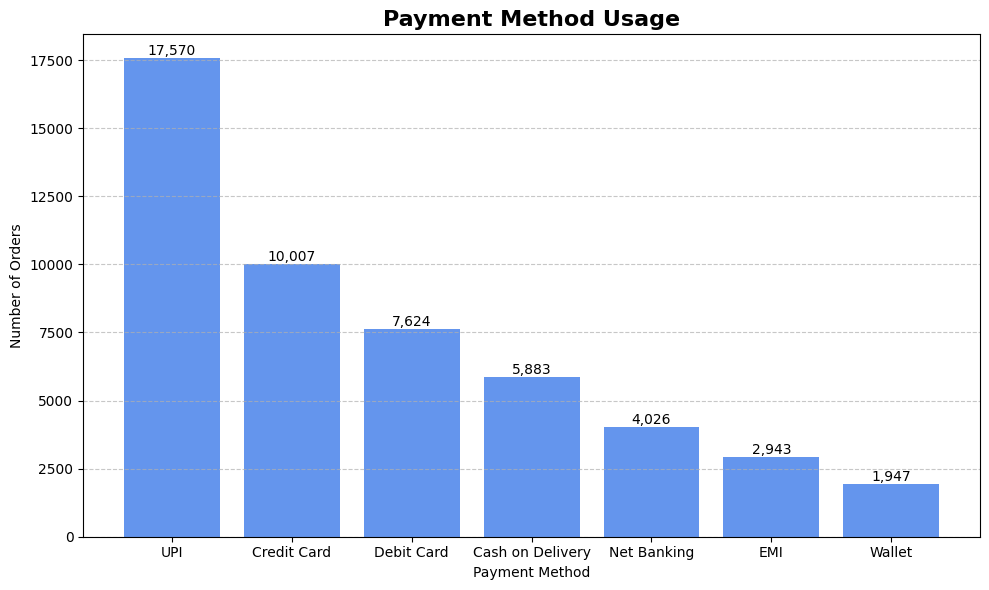

In [39]:
# Plot 7: Payment Method Usage
plt.figure(figsize=(10, 6))
bars = plt.bar(payment_counts['payment_method'], payment_counts['order_count'], color='cornflowerblue')

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{int(bar.get_height()):,}',
             ha='center', va='bottom')

plt.title('Payment Method Usage', fontsize=16, fontweight='bold')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('charts/07_payment_method_usage.png', dpi=150, bbox_inches='tight')
plt.show()

### 8. Age Distribution

In [44]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        10000 non-null  object 
 1   first_name         10000 non-null  object 
 2   last_name          10000 non-null  object 
 3   email              10000 non-null  object 
 4   phone              10000 non-null  int64  
 5   city               10000 non-null  object 
 6   state              10000 non-null  object 
 7   pincode            10000 non-null  int64  
 8   gender             10000 non-null  object 
 9   age                10000 non-null  int64  
 10  segment            10000 non-null  object 
 11  registration_date  10000 non-null  object 
 12  last_login_date    10000 non-null  object 
 13  is_verified        10000 non-null  int64  
 14  is_active          10000 non-null  int64  
 15  total_orders       10000 non-null  int64  
 16  total_spent        1000

In [46]:
display(customers['age'].describe())
print('Missing ages:', customers['age'].isna().sum())

,age
count,10000.00000
mean,41.67630
std,13.83438
min,18.00000
25%,30.00000
50%,42.00000
75%,54.00000
max,65.00000


Missing ages: 0


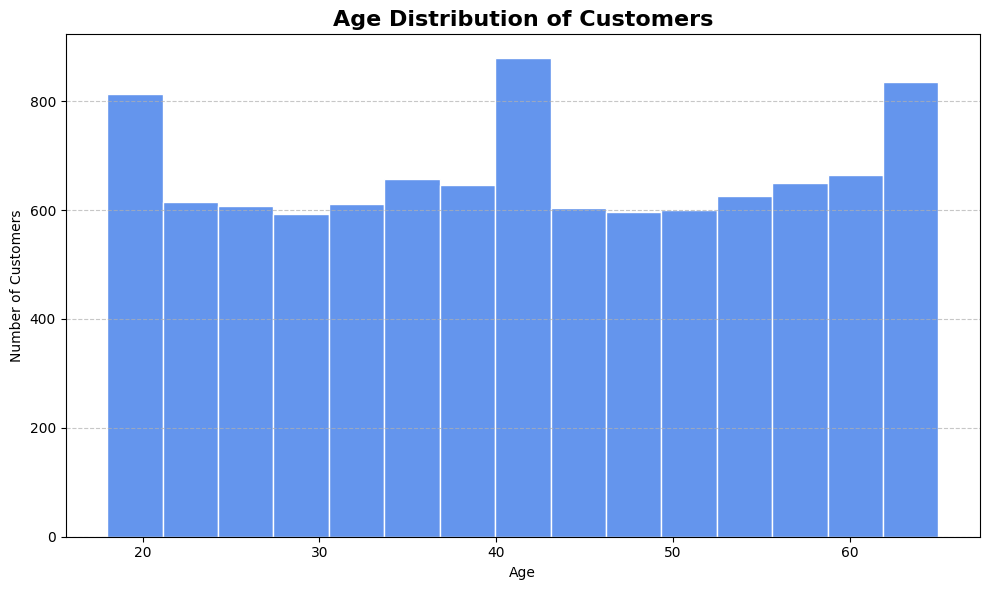

In [48]:
# Plot 8: Age Distribution
plt.figure(figsize=(10, 6))
plt.hist(customers['age'].dropna(), bins=15, color='cornflowerblue', edgecolor='white')
plt.title('Age Distribution of Customers', fontsize=16, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('charts/08_age_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [49]:
# loading returns dataset
returns = pd.read_csv('returns DA.csv')
returns.head()

,return_id,order_id,customer_id,return_date,reason,return_amount,refund_status,refund_date,return_condition,remarks
0,RET00001,ORD000015,CUST05470,23-12-2024,Size Issue,24167.33,Pending,30-12-2024,Damaged,Customer initiated return within 7 day window
1,RET00002,ORD000017,CUST07581,01-11-2023,Defective Product,11698.27,Refunded,06-11-2023,Damaged,Customer initiated return within 7 day window
2,RET00003,ORD000038,CUST05691,01-05-2025,Wrong Product Delivered,11147.74,Refunded,06-05-2025,Damaged,Customer initiated return within 7 day window
3,RET00004,ORD000054,CUST03170,20-06-2025,Duplicate Order,9284.55,Refunded,24-06-2025,Acceptable,Customer initiated return within 7 day window
4,RET00005,ORD000072,CUST09318,16-03-2025,Duplicate Order,36912.59,Refunded,23-03-2025,Good,Customer initiated return within 7 day window


### 9. Return Reasons

In [50]:
return_reasons = returns['reason'].value_counts().reset_index()
return_reasons.columns = ['reason', 'return_count']
display(return_reasons)

,reason,return_count
0,Size Issue,1196
1,Changed Mind,1150
2,Damaged in Transit,1143
3,Wrong Product Delivered,1135
4,Defective Product,1134
5,Not as Described,1125
6,Duplicate Order,1081
7,Quality Issue,1075
8,Delayed Delivery,484
9,Better Price Found,477


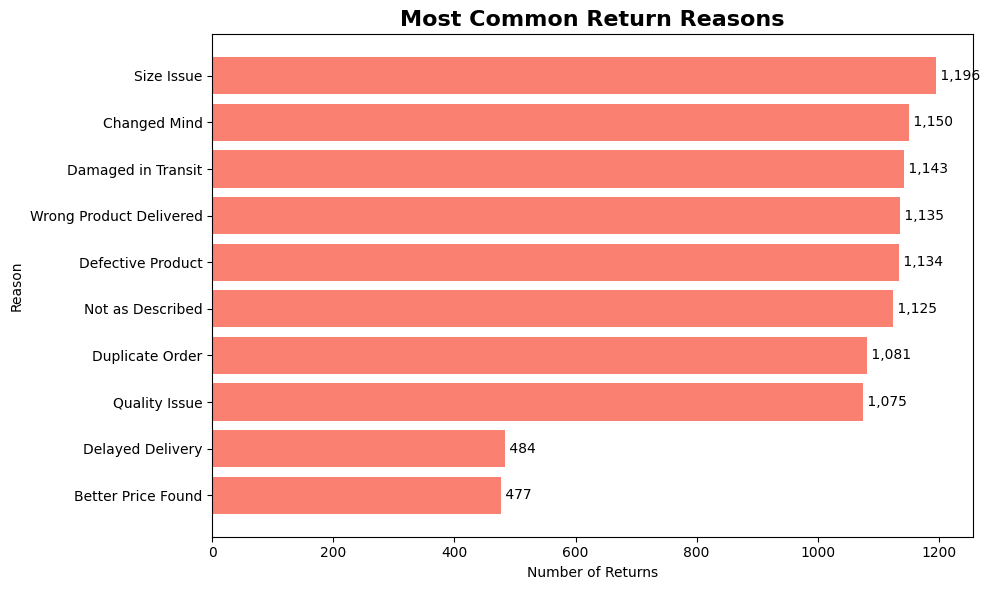

In [51]:
# Plot 9: Return Reasons
plt.figure(figsize=(10, 6))
plt.barh(return_reasons['reason'], return_reasons['return_count'], color='salmon')
plt.gca().invert_yaxis()

for i, v in enumerate(return_reasons['return_count']):
    plt.text(v, i, f' {v:,}', va='center')

plt.title('Most Common Return Reasons', fontsize=16, fontweight='bold')
plt.xlabel('Number of Returns')
plt.ylabel('Reason')
plt.tight_layout()
plt.savefig('charts/09_return_reasons.png', dpi=150, bbox_inches='tight')
plt.show()

### 10. AOV by Customer Segment

In [52]:
# Delivered orders only, with segment attached
delivered = orders[orders['status'] == 'Delivered']
delivered_seg = delivered.merge(customers[['customer_id', 'segment']], on='customer_id', how='left')

aov_segment = delivered_seg.groupby('segment').agg(
    net_revenue=('final_amount', 'sum'),
    delivered_orders=('order_id', 'count')
).reset_index()

aov_segment['aov'] = aov_segment['net_revenue'] / aov_segment['delivered_orders']
aov_segment = aov_segment.sort_values('aov', ascending=False)

display(aov_segment)
print('Orders with no matching segment:', delivered_seg['segment'].isna().sum())

,segment,net_revenue,delivered_orders,aov
0,Budget,3.064395e+08,4718,64951.141594
1,Inactive,1.151860e+07,181,63638.692762
4,Regular,9.550491e+08,15050,63458.413567
2,New,2.641842e+08,4175,63277.655696
3,Premium,5.166672e+08,8375,61691.604276


Orders with no matching segment: 0


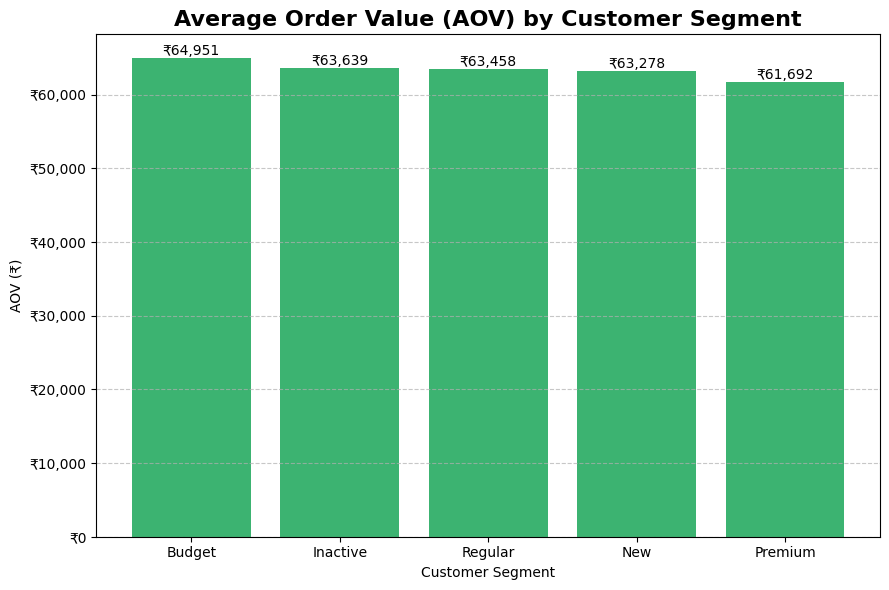

In [53]:
# Plot 10: AOV by Customer Segment
plt.figure(figsize=(9, 6))
bars = plt.bar(aov_segment['segment'], aov_segment['aov'], color='mediumseagreen')

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'₹{bar.get_height():,.0f}',
             ha='center', va='bottom')

plt.gca().yaxis.set_major_formatter(inr)
plt.title('Average Order Value (AOV) by Customer Segment', fontsize=16, fontweight='bold')
plt.xlabel('Customer Segment')
plt.ylabel('AOV (₹)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('charts/10_aov_by_segment.png', dpi=150, bbox_inches='tight')
plt.show()